# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Thomas Jeremy S. Gonzaga
- _Student No._: 2023-16222
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- 

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

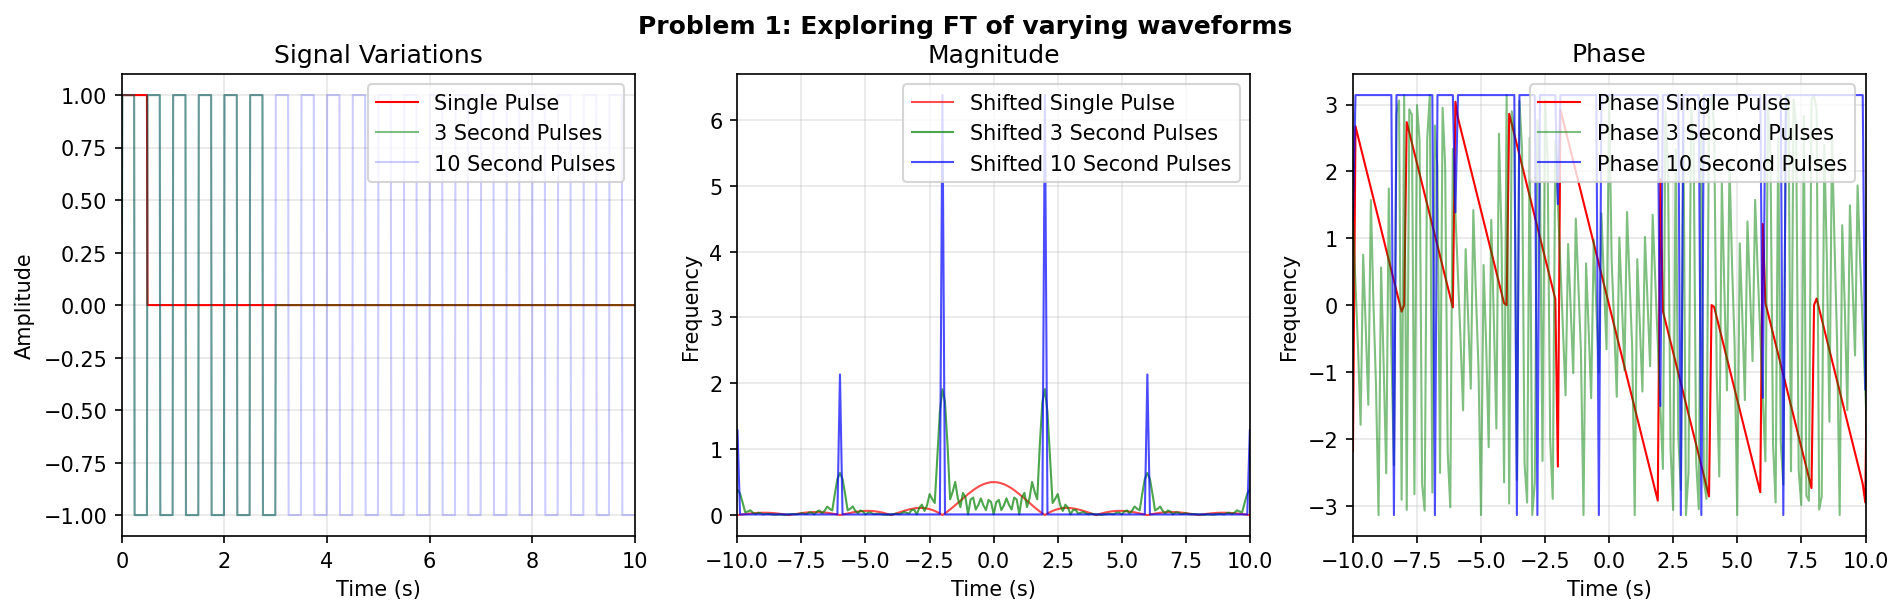

In [2]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
dt = t[1] - t[0]
f0 = 2 # frequency

# main signal, sinusoidal
square_full = np.sign(np.sin(2 * np.pi * f0 * t))

# pulse types
x1 = np.where(t <= 0.5, 1.0, 0.0) # one pulse
x2 = np.where(t <= 3.0, square_full, 0.0) # 3 seconds
x3 = np.where(t <= 10.0, square_full, 0.0) # 10 seconds

# shifted ffts, shifts zero-frequency to the center of the spectrum
x1_shifted = np.fft.fftshift(np.fft.fft(x1)*dt)
x2_shifted = np.fft.fftshift(np.fft.fft(x2)*dt)
x3_shifted = np.fft.fftshift(np.fft.fft(x3)*dt)

# frequency axis, calculated frequency values at each point
frequency_shifted = np.fft.fftshift(np.fft.fftfreq(len(t), d=dt))

# Axis Plots

fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=150)
fig.suptitle('Problem 1: Exploring FT of varying waveforms', fontweight='bold')

# signal and variations
axes[0].plot(t, x1, label='Single Pulse', color='red', alpha=1, linewidth=1)
axes[0].plot(t, x2, label='3 Second Pulses', color='green', alpha=0.5, linewidth=1)
axes[0].plot(t, x3, label='10 Second Pulses', color='blue', alpha=0.2, linewidth=1)

# magnitudes
axes[1].plot(frequency_shifted, np.abs(x1_shifted), label='Shifted Single Pulse', color='red', alpha=0.7, linewidth=1)
axes[1].plot(frequency_shifted, np.abs(x2_shifted), label='Shifted 3 Second Pulses', color='green', alpha=0.7, linewidth=1)
axes[1].plot(frequency_shifted, np.abs(x3_shifted), label='Shifted 10 Second Pulses', color='blue', alpha=0.7, linewidth=1)

axes[2].plot(frequency_shifted, np.angle(x1_shifted), label='Phase Single Pulse', color='red', alpha=1, linewidth=1)
axes[2].plot(frequency_shifted, np.angle(x2_shifted), label='Phase 3 Second Pulses', color='green', alpha=0.5, linewidth=1)
axes[2].plot(frequency_shifted, np.angle(x3_shifted), label='Phase 10 Second Pulses', color='blue', alpha=0.7, linewidth=1)

axes[0].set_title('Signal Variations')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_xlim([0, 10])
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right')

axes[1].set_title('Magnitude')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Frequency')
axes[1].set_xlim([-10, 10])
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

axes[2].set_title('Phase')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Frequency')
axes[2].set_xlim([-10, 10])
axes[2].grid(True, alpha=0.3)
axes[2].legend(loc='upper right')

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [3]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 2500
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

freq_axis = np.fft.fftfreq(N, d=dt)

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

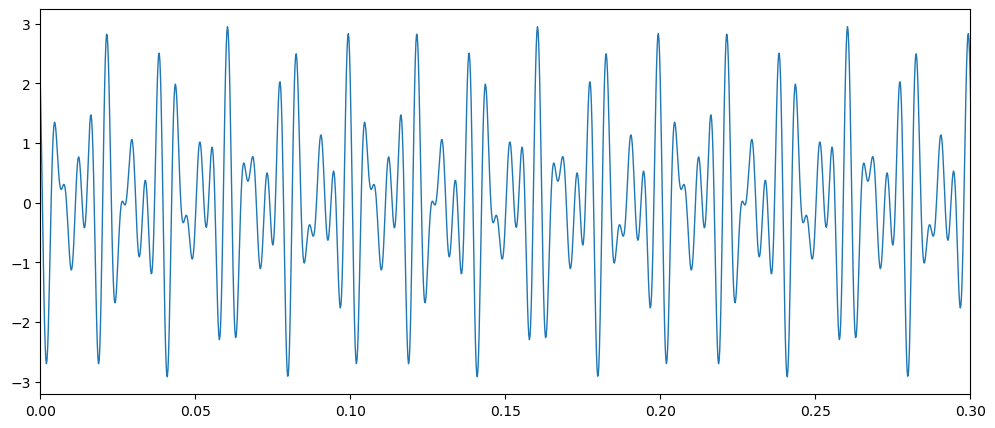

In [4]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original, linewidth=1)
ax.set_xlim(0,0.3)

/opt/conda/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/conda/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


(-500.0, 500.0)

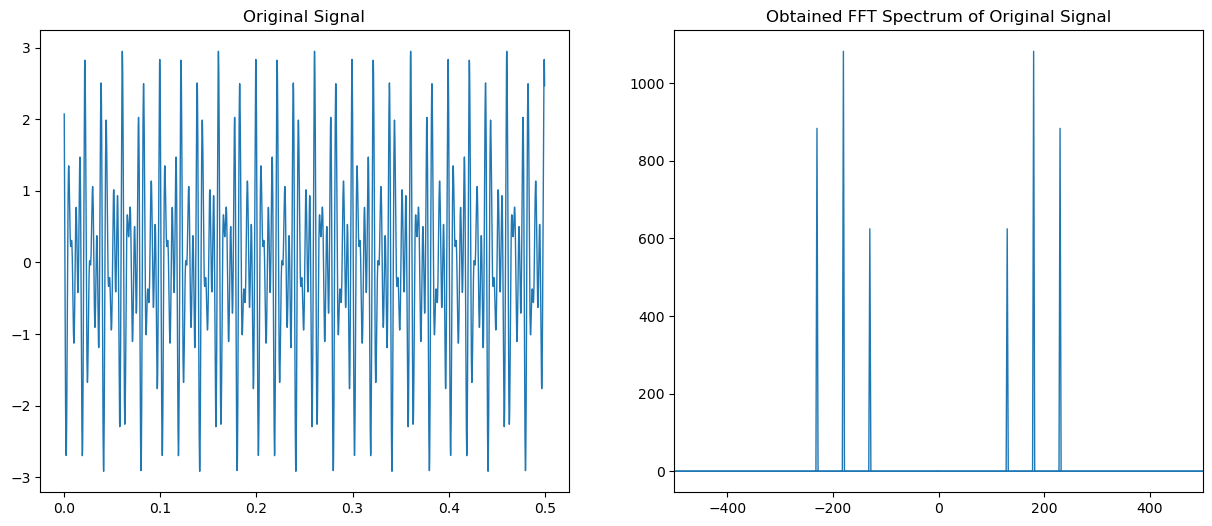

In [5]:
#FILL: Plot the fourier transform of the clean, original signal

fft_clean = np.fft.fft(signal_original)

fig, axes = plt.subplots(1, 2, figsize = (15, 6))

axes[0].plot(t_, signal_original, linewidth=1)
axes[0].set_title('Original Signal')

axes[1].plot(freq_axis, fft_clean, linewidth=1)
axes[1].set_title('Obtained FFT Spectrum of Original Signal')
axes[1].set_xlim(-500, 500)

In [6]:
rng = np.random.default_rng(67)

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point

#Noisy data here
noisy_data5 = signal_original + noise*5
noisy_data1 = signal_original + noise

fft_clean_from_noise5 = np.fft.fft(noisy_data5)
fft_clean_from_noise1 = np.fft.fft(noisy_data1)

Text(0.5, 1.0, 'Recovered FFT Spectrum from Less Noisy Data')

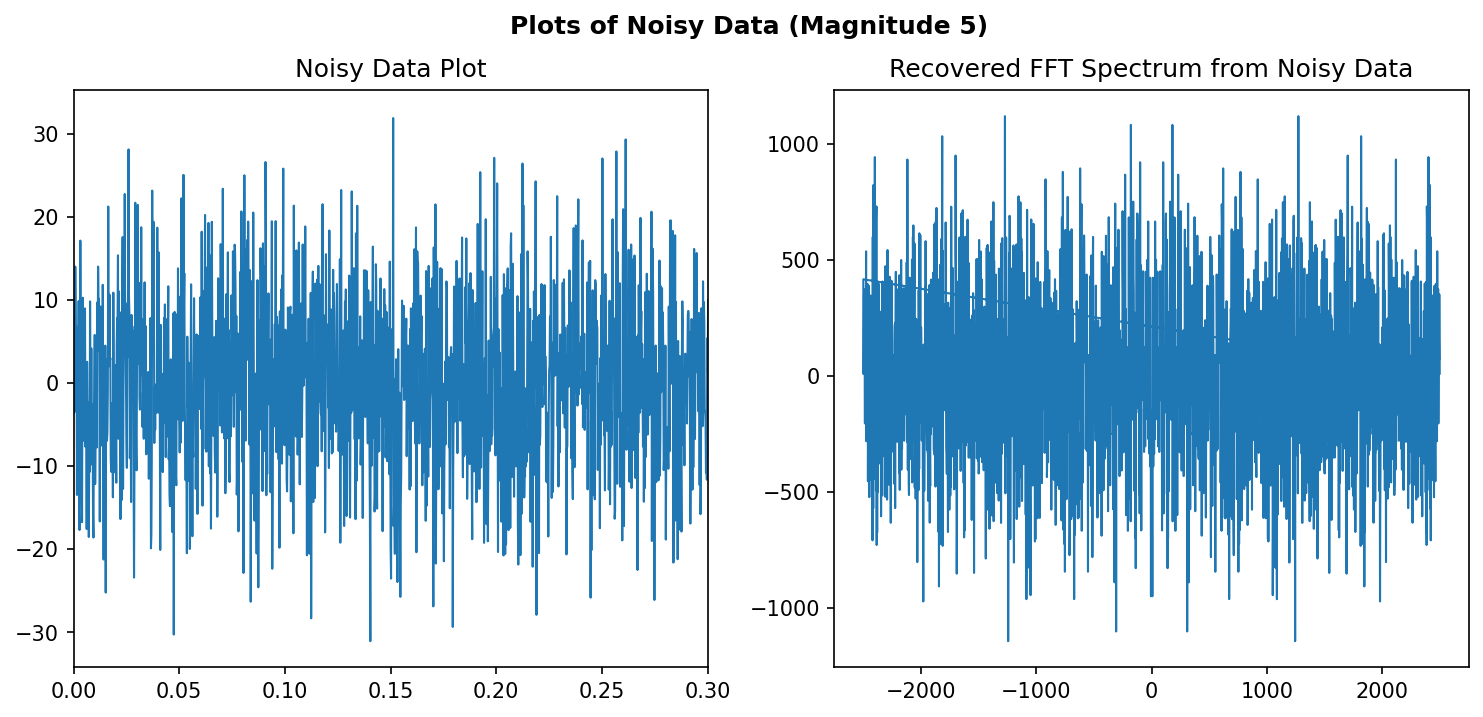

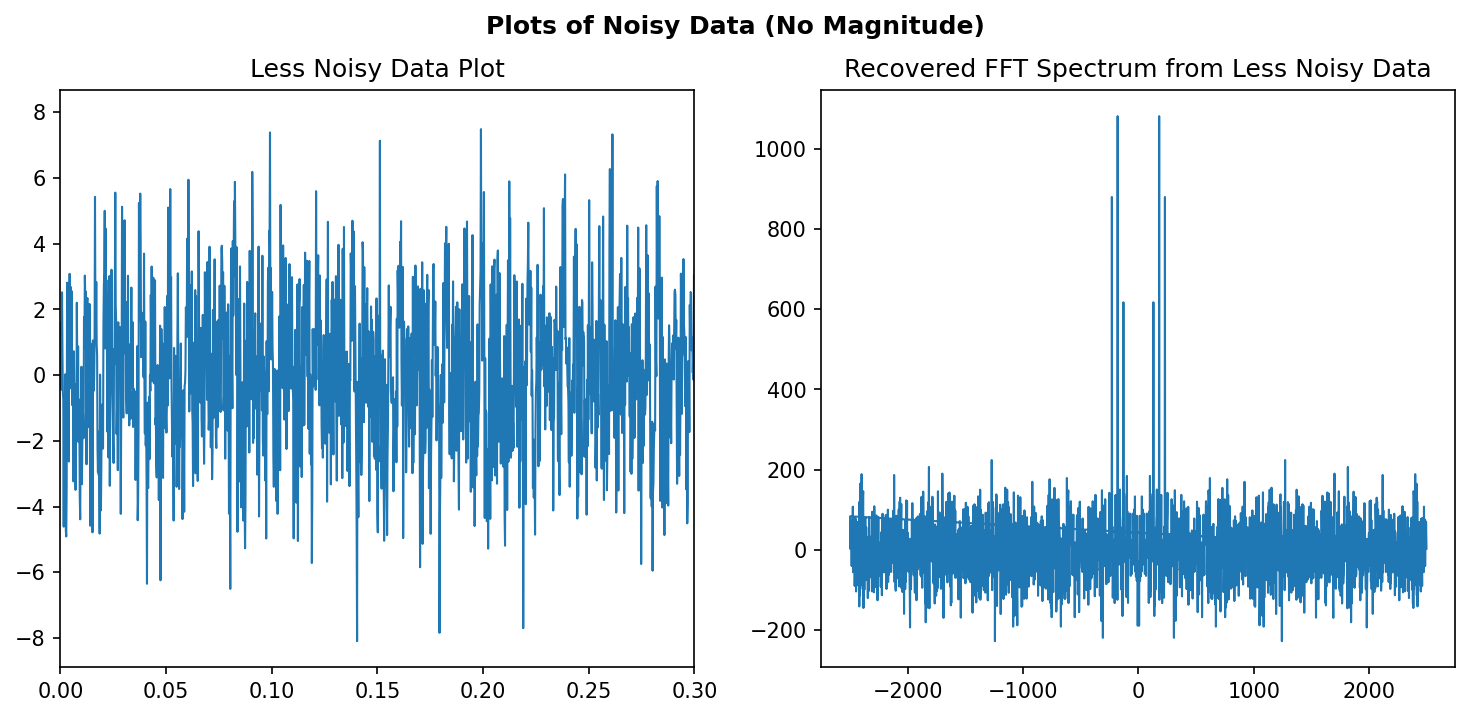

In [7]:
fig, axes = plt.subplots(1, 2, figsize= (12,5), dpi=150)
fig.suptitle('Plots of Noisy Data (Magnitude 5)', fontweight='bold')
axes[0].plot(t_, noisy_data5, linewidth=1)
axes[0].set_xlim(0,0.3)
axes[0].set_title('Noisy Data Plot')

axes[1].plot(freq_axis, fft_clean_from_noise5, linewidth=1)
axes[1].set_title('Recovered FFT Spectrum from Noisy Data')

# Less Noise

fig, axes = plt.subplots(1, 2, figsize= (12,5), dpi=150)
fig.suptitle('Plots of Noisy Data (No Magnitude)', fontweight='bold')

axes[0].plot(t_, noisy_data1, linewidth=1)
axes[0].set_xlim(0,0.3)
axes[0].set_title('Less Noisy Data Plot')

axes[1].plot(freq_axis, fft_clean_from_noise1, linewidth=1)
axes[1].set_title('Recovered FFT Spectrum from Less Noisy Data')

Text(0.5, 1.0, 'Magnitude of Windowed FFT Noisy Data')

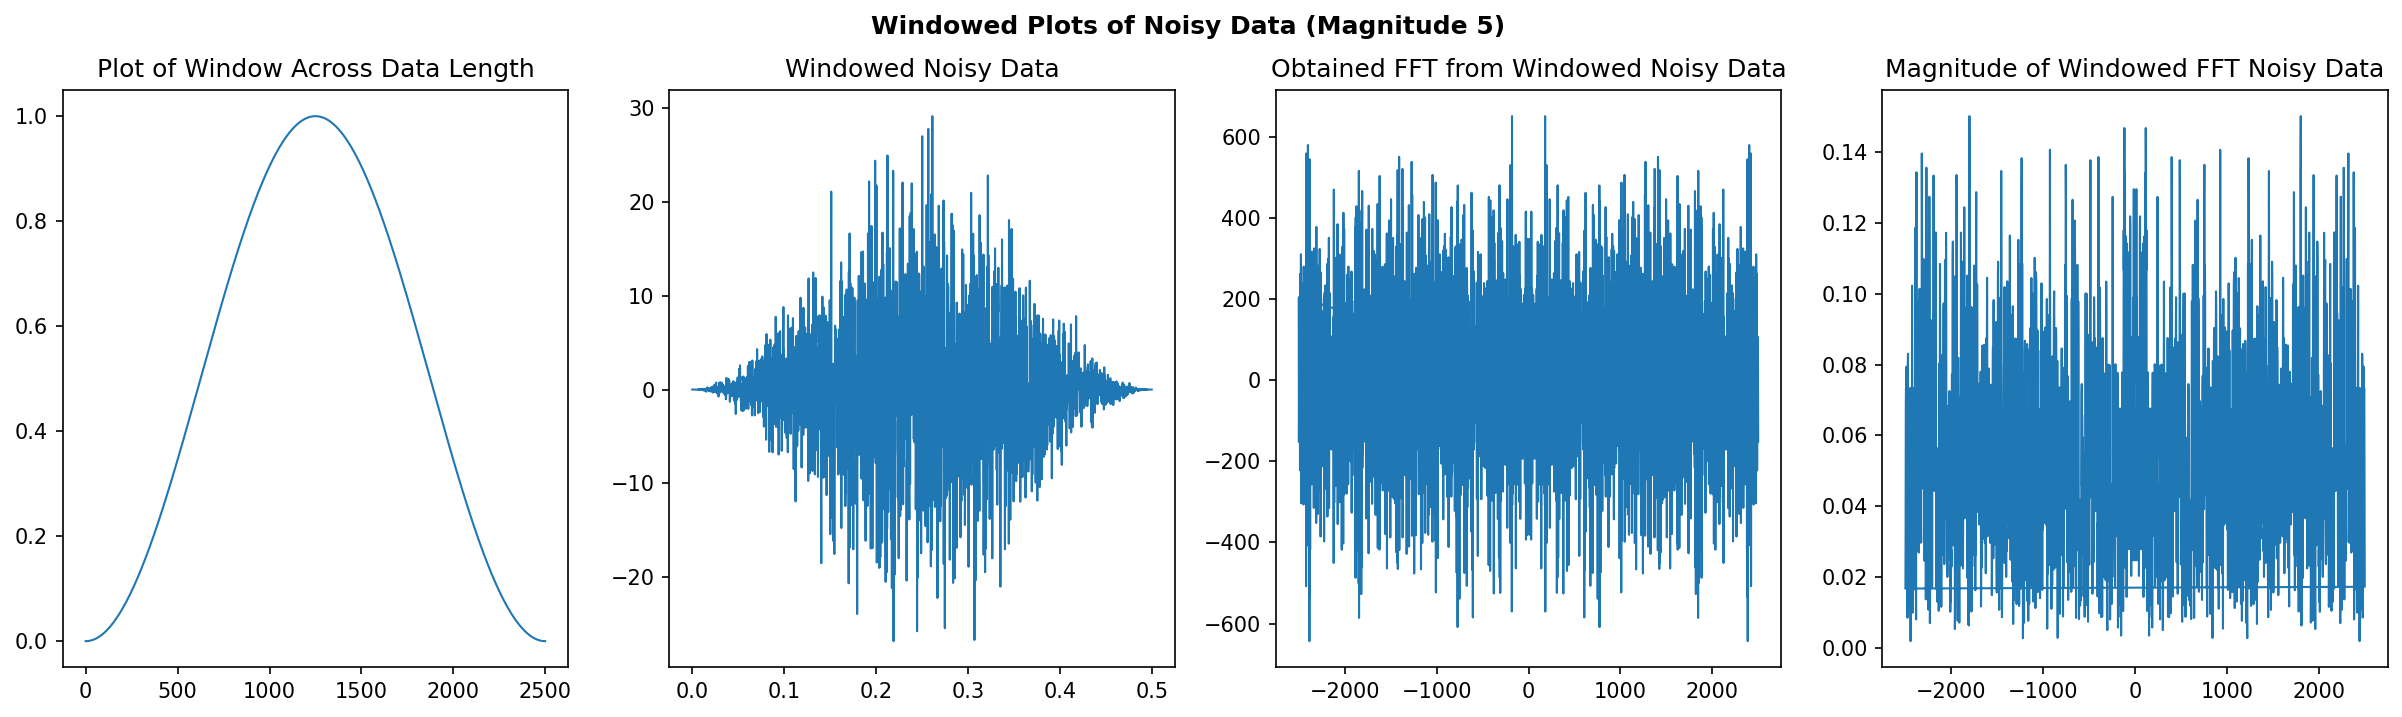

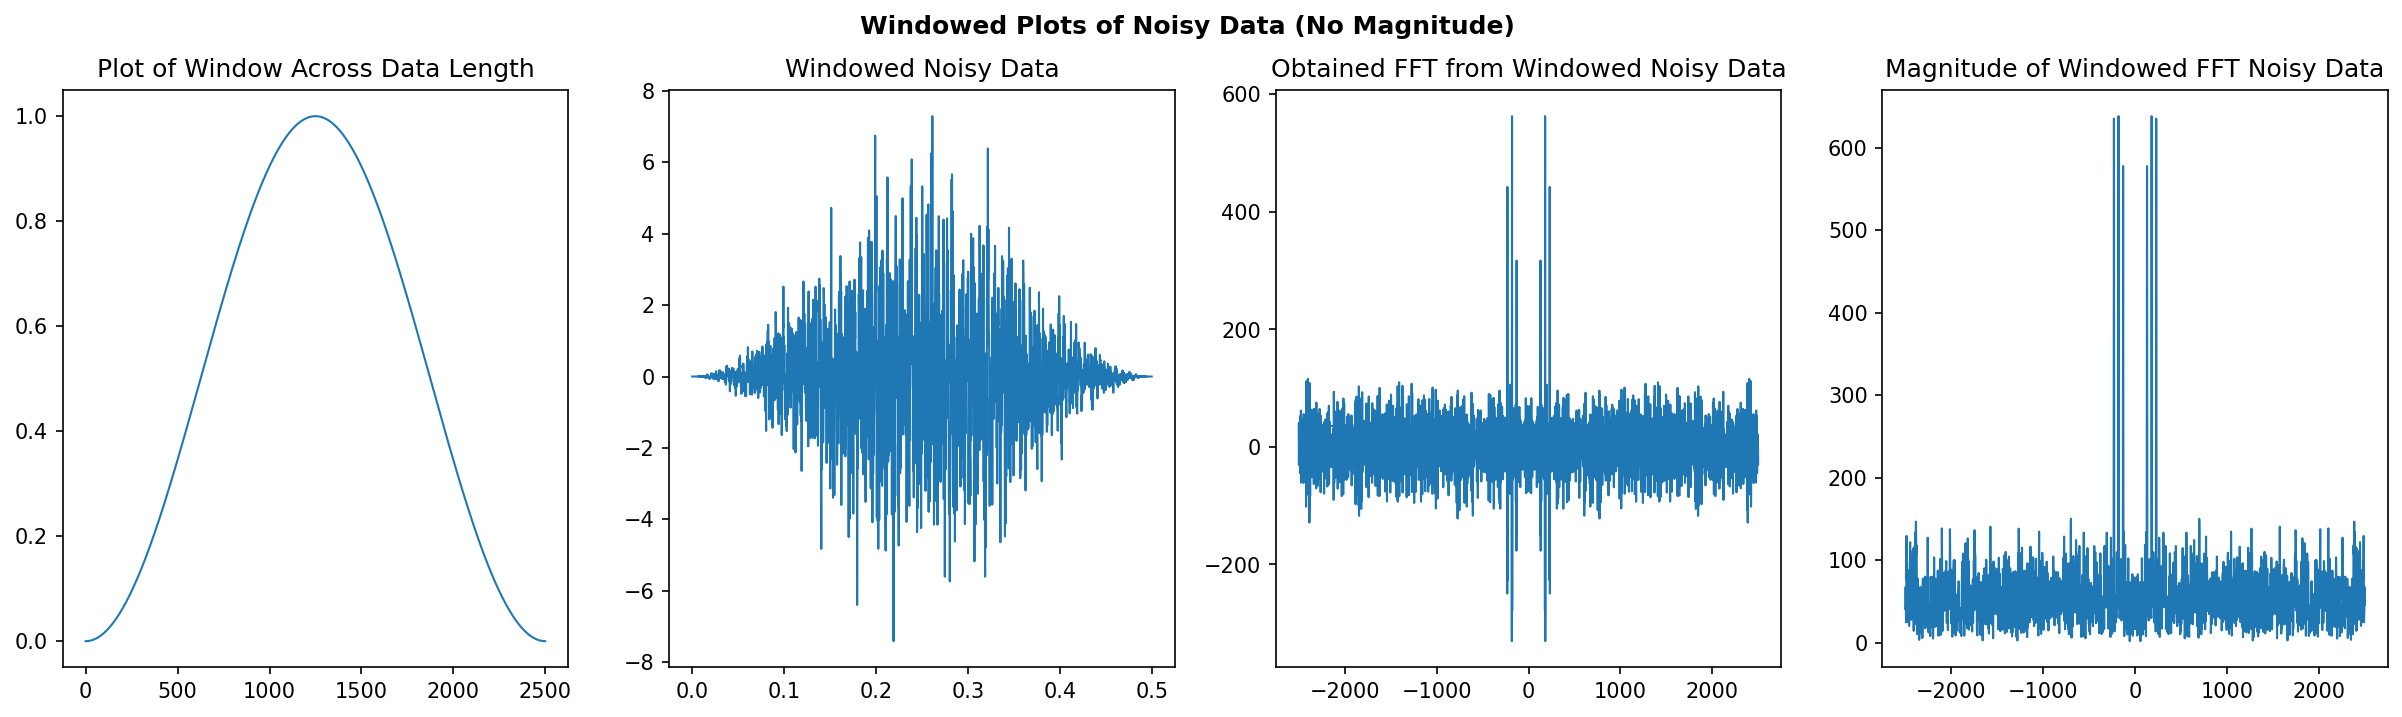

In [8]:
# 3.) Add a window (Hann)
window = np.hanning(len(noisy_data5)) #Create a window the size of the data length

noisy_data5_windowed = noisy_data5 * window
noisy_data1_windowed = noisy_data1 * window

# shifted for magnitude
data5_window_shifted5 = np.fft.fftshift(np.fft.fft(noisy_data5_windowed)*dt)
data1_window_shifted5 = np.fft.fftshift(np.fft.fft(noisy_data1_windowed)*dt)

# 4.) Get fft of the noisy signal
fft_clean_from_windowed5 = np.fft.fft(noisy_data5_windowed)
fft_clean_from_windowed1 = np.fft.fft(noisy_data1_windowed)

fig, axes = plt.subplots(1, 4, figsize= (20,5), dpi=150)
fig.suptitle('Windowed Plots of Noisy Data (Magnitude 5)', fontweight='bold')
axes[0].plot(window, linewidth=1)
axes[0].set_title('Plot of Window Across Data Length')

axes[1].plot(t_, noisy_data5_windowed, linewidth=1)
axes[1].set_title('Windowed Noisy Data')

axes[2].plot(freq_axis, fft_clean_from_windowed5, linewidth=1)
axes[2].set_title('Obtained FFT from Windowed Noisy Data')

# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

axes[3].plot(freq_axis, np.abs(data5_window_shifted5), linewidth=1)
axes[3].set_title('Magnitude of Windowed FFT Noisy Data')

##### fig 2

fig, axes = plt.subplots(1, 4, figsize= (20,5), dpi=150)
fig.suptitle('Windowed Plots of Noisy Data (No Magnitude)', fontweight='bold')

axes[0].plot(window, linewidth=1)
axes[0].set_title('Plot of Window Across Data Length')

axes[1].plot(t_, noisy_data1_windowed, linewidth=1)
axes[1].set_title('Windowed Noisy Data')

axes[2].plot(freq_axis, fft_clean_from_windowed1, linewidth=1)
axes[2].set_title('Obtained FFT from Windowed Noisy Data')

# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

axes[3].plot(freq_axis, np.abs(fft_clean_from_windowed1), linewidth=1)
axes[3].set_title('Magnitude of Windowed FFT Noisy Data')

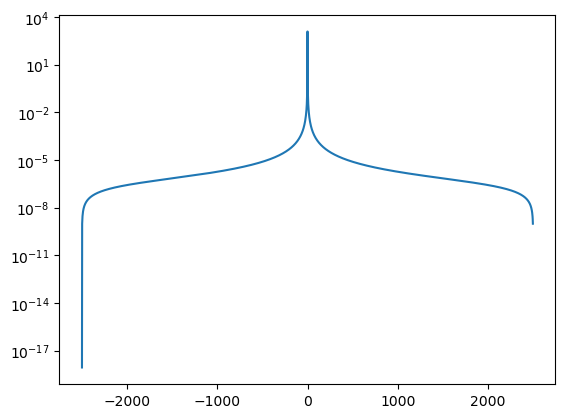

In [9]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [10]:
# noisyFourier = np.fft.fft(noisy_data5*window)
# noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data5*window)))

In [11]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
# 5.) Filter Below a Threshold

threshold = np.max(np.abs(fft_clean_from_windowed5)) * 0.2 # the decimal values is the % range where peaks above it are kept
fft_filtered = np.where(np.abs(fft_clean_from_windowed5) > threshold, fft_clean_from_windowed5, 0) # keeps the fft values above the threshold and removes values under

In [12]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

Text(0.5, 1.0, 'Recovered Signal')

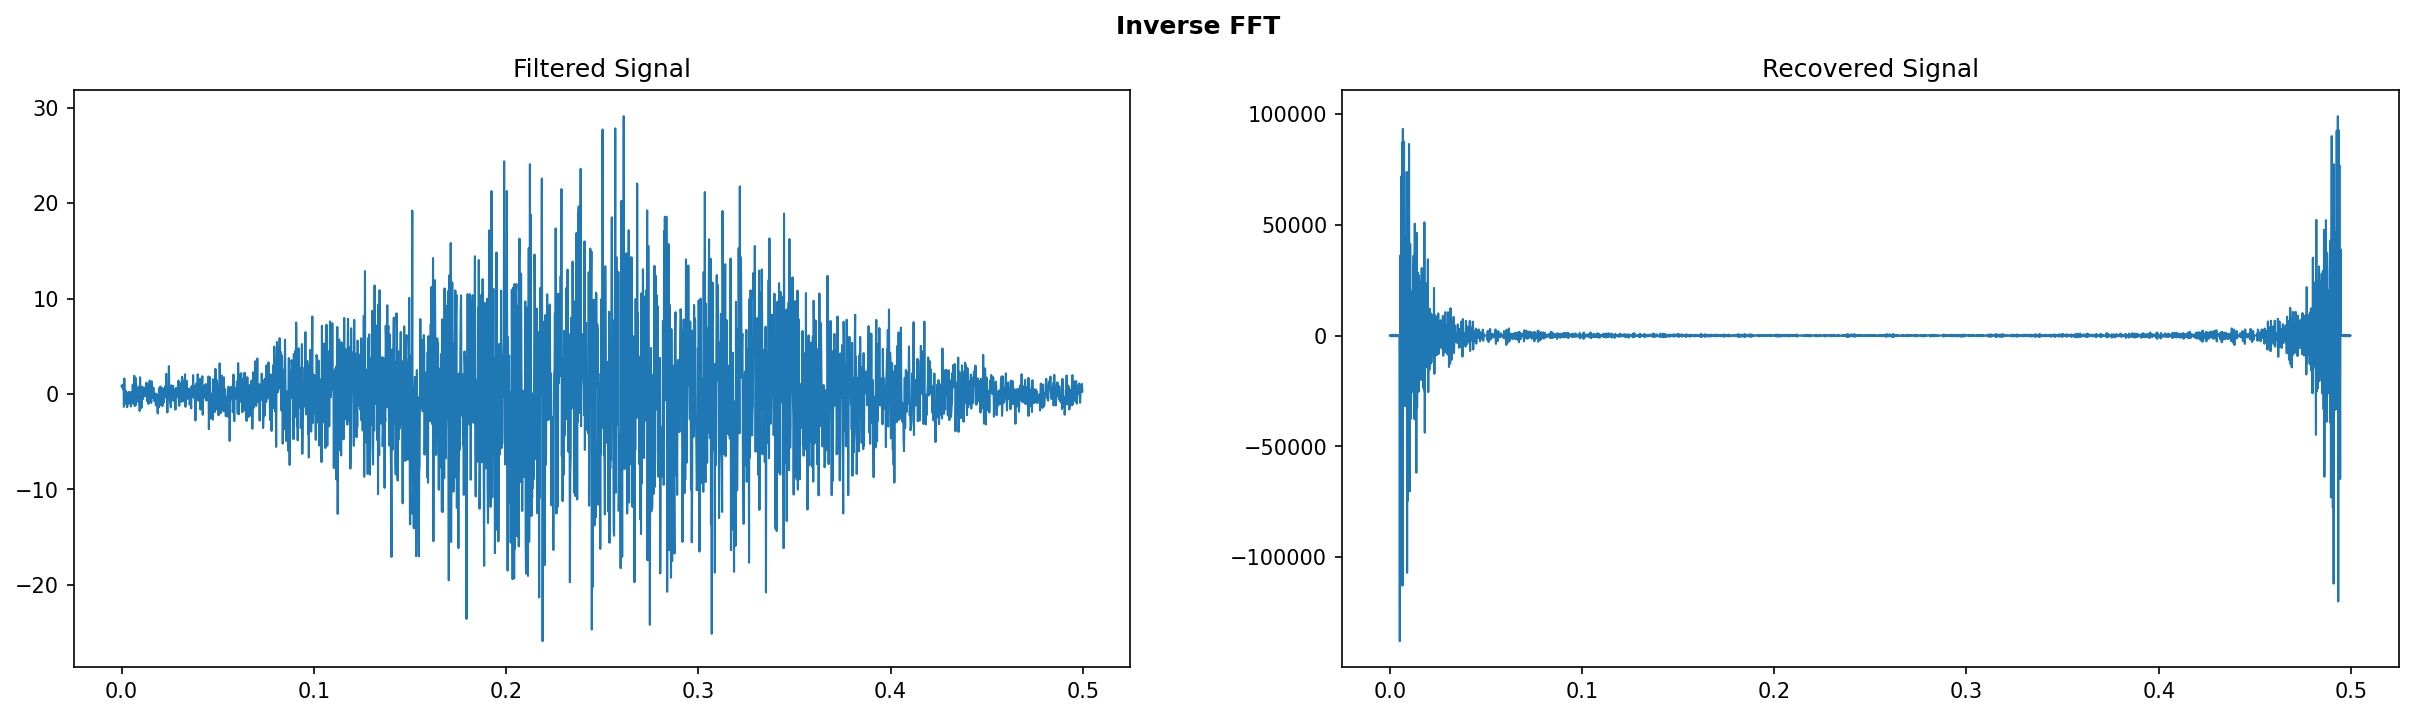

In [13]:
# 6.) get the inverse fft
signal_filtered = np.fft.ifft(fft_filtered).real
signal_recovered = fft_filtered / np.where(window > 1e-3, window, 1)

fig, axes = plt.subplots(1, 2, figsize= (20,5), dpi=150)
fig.suptitle('Inverse FFT', fontweight='bold')

axes[0].plot(t_, signal_filtered, linewidth=1)
axes[0].set_title('Filtered Signal')

axes[1].plot(t_, signal_recovered, linewidth=1)
axes[1].set_title('Recovered Signal')

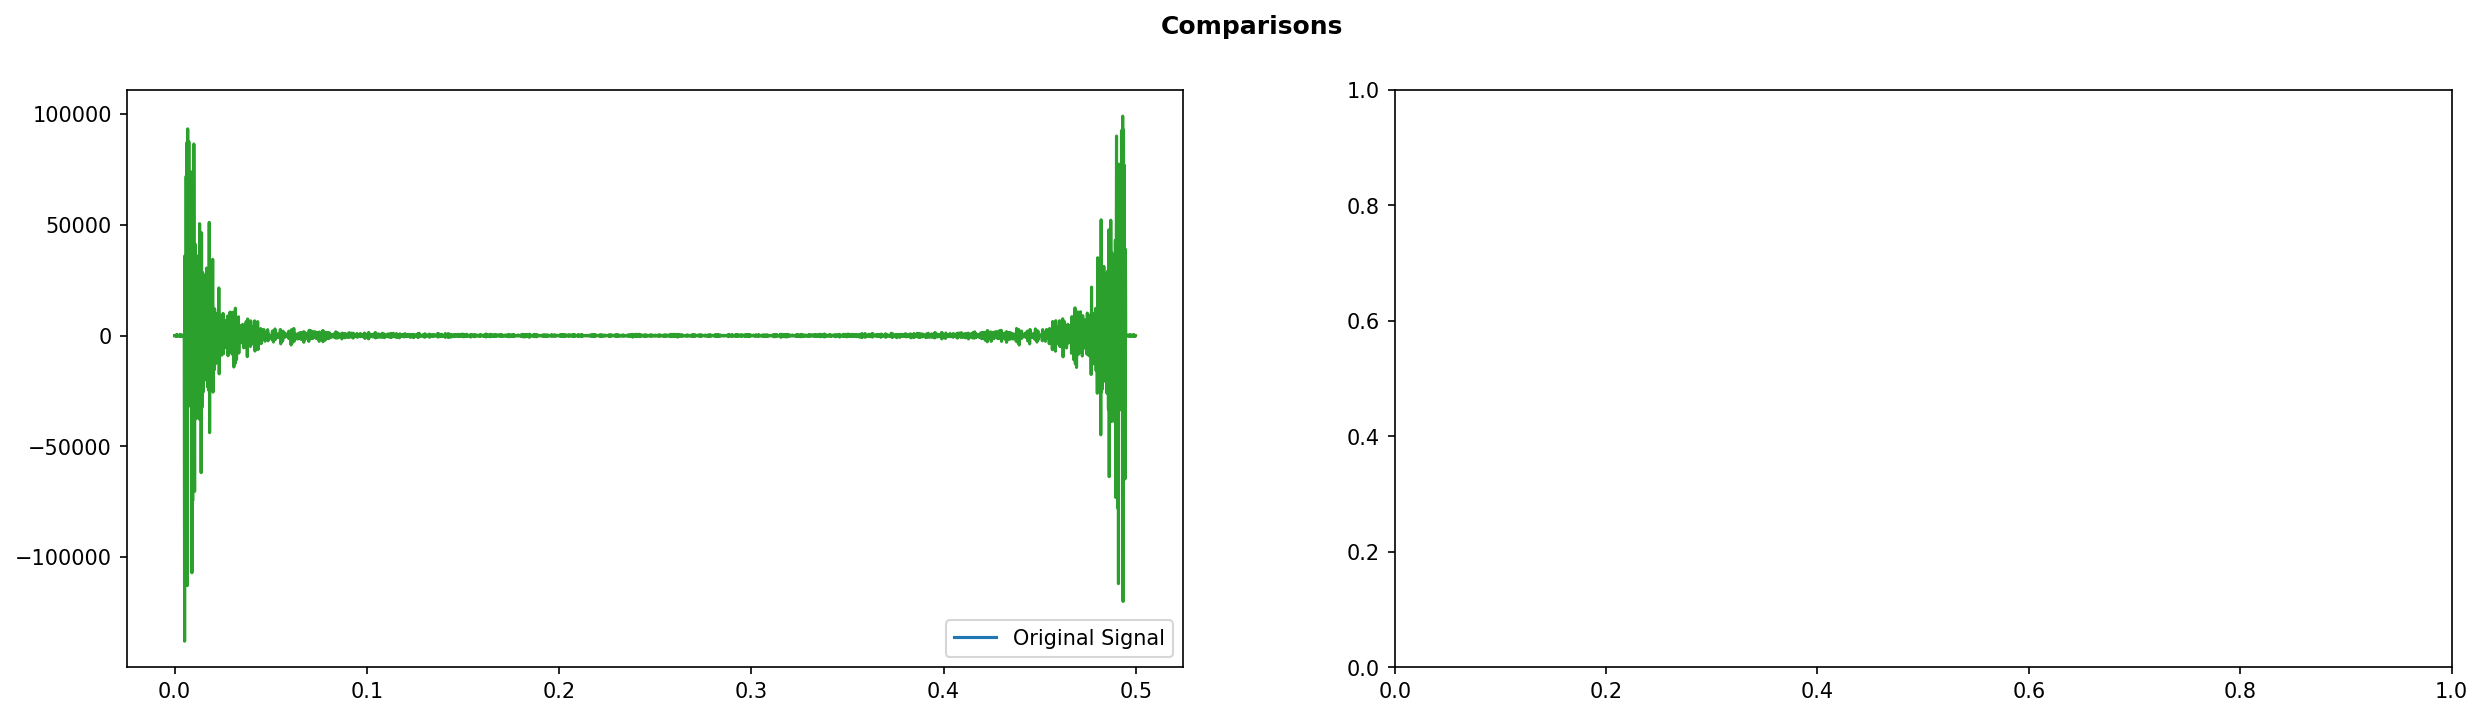

In [14]:
# 7.) compare the result

fig, axes = plt.subplots(1, 2, figsize= (20,5), dpi=150)
fig.suptitle('Comparisons', fontweight='bold')

axes[0].plot(t_, signal_original, label='Original Signal')
axes[0].plot(t_, noisy_data5)
axes[0].plot(t_, signal_recovered)
axes[0].legend()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

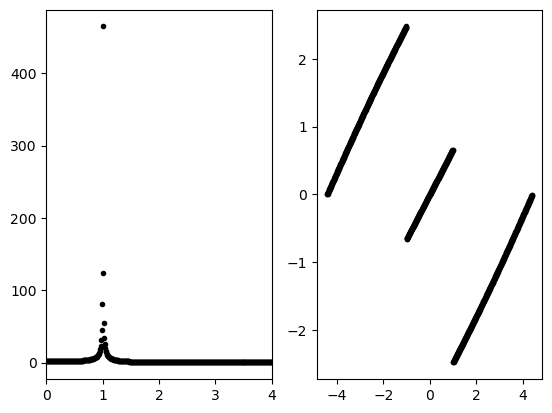

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

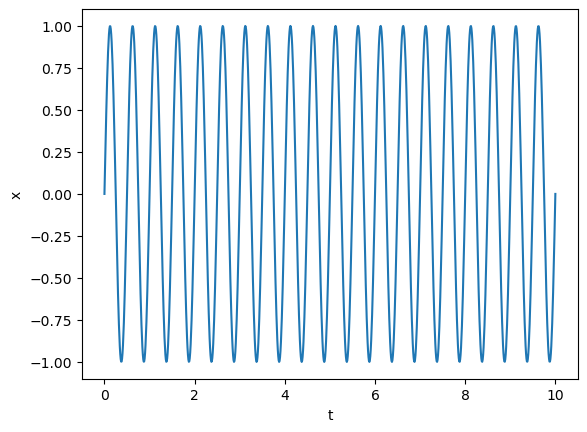

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

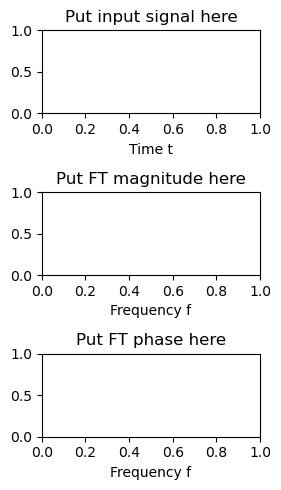

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

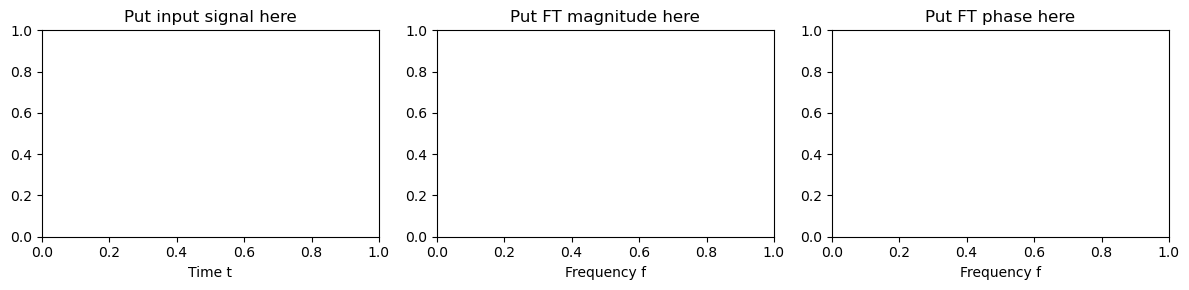

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

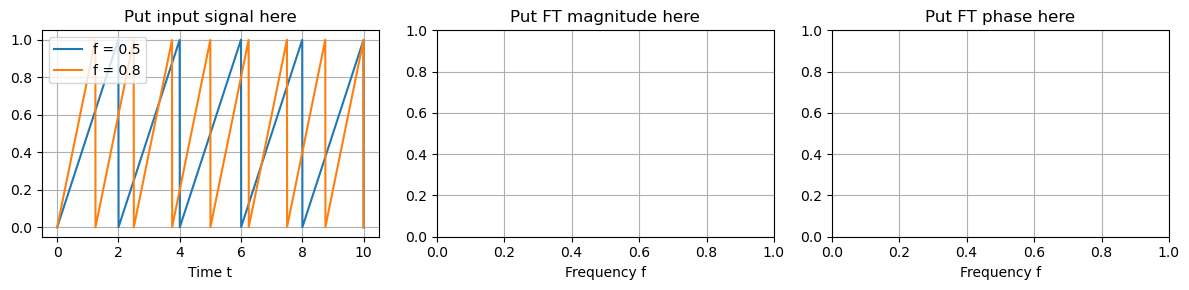

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



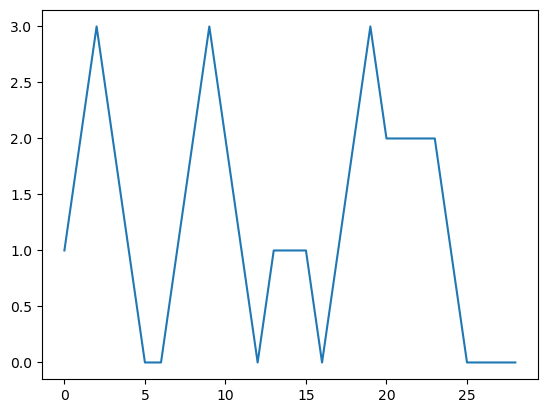

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [25]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [26]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

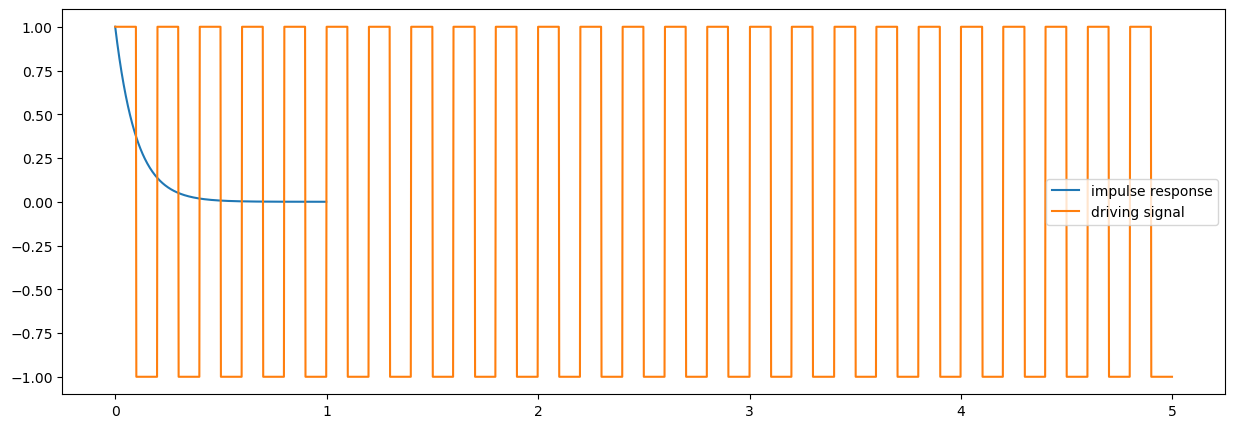

In [27]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [28]:
response = np.convolve(input_signal, h_t, mode = "same")

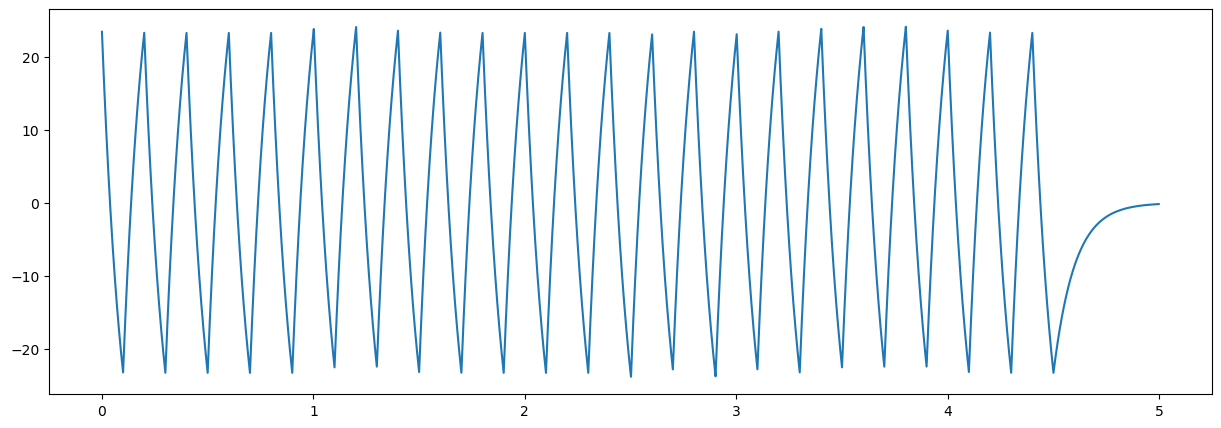

In [29]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [30]:
fourier_length = len(h_t) + len(input_signal) - 1

In [31]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [32]:
fourier_response = fourier_h*fourier_input 

In [33]:
response = np.real(np.fft.ifft(fourier_response))

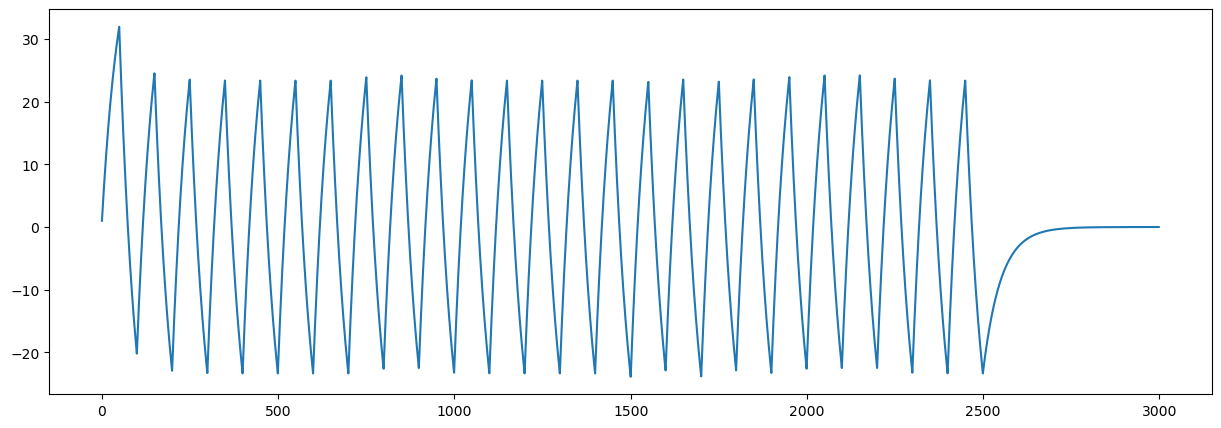

In [34]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)